# BÀI TẬP CHƯƠNG 7: HỒI QUY TUYẾN TÍNH BỘI (MULTIPLE LINEAR REGRESSION)
**Dự đoán doanh số bán hàng hàng tháng (Sales) dựa trên chi phí quảng cáo TV, Radio, Newspaper, Online**

---
### Bảng mô tả biến số:
| Biến số | Mô tả | Đơn vị tính |
| :--- | :--- | :--- |
| **TV** | Chi phí quảng cáo trên truyền hình | ngàn USD |
| **Radio** | Chi phí quảng cáo trên đài phát thanh | ngàn USD |
| **Newspaper** | Chi phí quảng cáo trên báo giấy | ngàn USD |
| **Online** | Chi phí quảng cáo trực tuyến | ngàn USD |
| **Sales** | Doanh số bán hàng hàng tháng | ngàn USD |

*Dữ liệu được thu thập từ file `regression_sales_data_1000.xlsx`.*


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid')


## Đọc dữ liệu và Khám phá tổng quan (Data Overview & EDA)

In [2]:
df = pd.read_excel('regression_sales_data_1000.xlsx')

print("Kich thuoc tap du lieu:", df.shape)
print("\n5 dong dau tien:")
display(df.head())

print("\nThong ke mo ta cac bien:")
display(df.describe().round(3))


Kich thuoc tap du lieu: (1000, 5)

5 dong dau tien:


,TV,Radio,Newspaper,Online,Sales
0,174.835708,43.993554,14.872326,1.843849,22.990653
1,143.086785,39.246337,22.832220,22.792300,24.000021
2,182.384427,30.596304,13.113701,31.727889,23.376987
3,226.151493,23.530632,20.380577,77.753753,26.818440
4,138.292331,36.982233,0.000000,51.131062,20.082341



Thong ke mo ta cac bien:


,TV,Radio,Newspaper,Online,Sales
count,1000.000,1000.000,1000.000,1000.000,1000.000
mean,150.979,30.708,25.355,39.783,22.600
std,48.922,9.975,14.186,20.193,4.627
min,0.000,0.596,0.000,0.000,8.787
25%,117.620,23.938,15.280,25.252,19.533
50%,151.265,30.631,24.996,40.004,22.715
75%,182.397,37.289,34.914,53.339,25.624
max,342.637,61.931,83.894,104.862,36.807


## Trực quan hóa dữ liệu (Data Visualization)

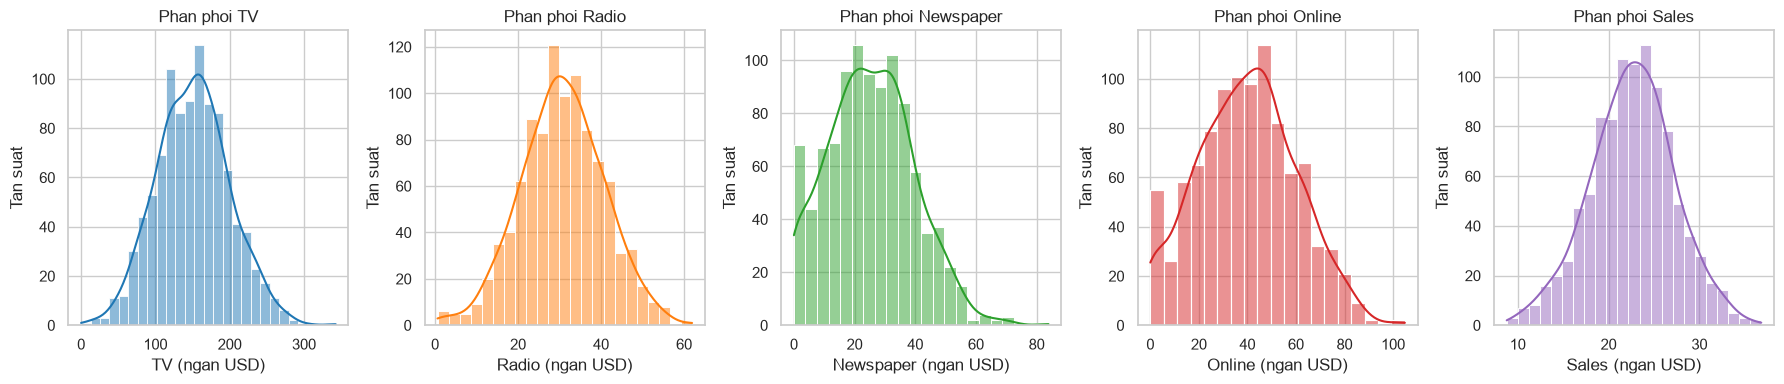

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
columns = ['TV', 'Radio', 'Newspaper', 'Online', 'Sales']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for i in range(len(columns)):
    col = columns[i]
    sns.histplot(df[col], kde=True, ax=axes[i], color=colors[i])
    axes[i].set_title(f'Phan phoi {col}')
    axes[i].set_xlabel(f'{col} (ngan USD)')
    axes[i].set_ylabel('Tan suat')

plt.tight_layout()
plt.show()


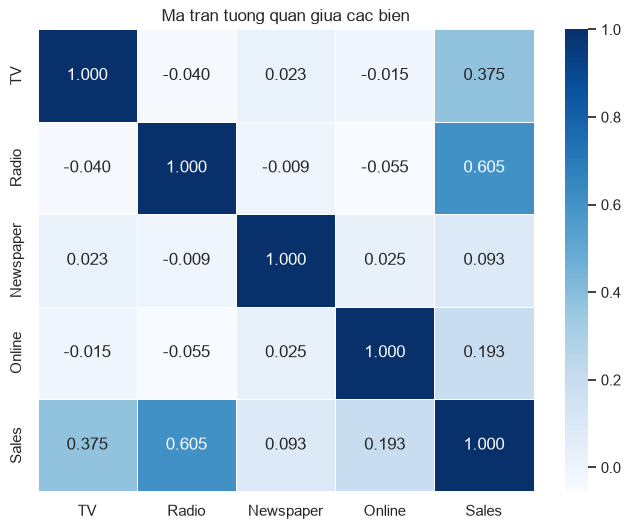

In [4]:
corr_matrix = df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.3f', linewidths=0.5)
plt.title('Ma tran tuong quan giua cac bien')
plt.show()


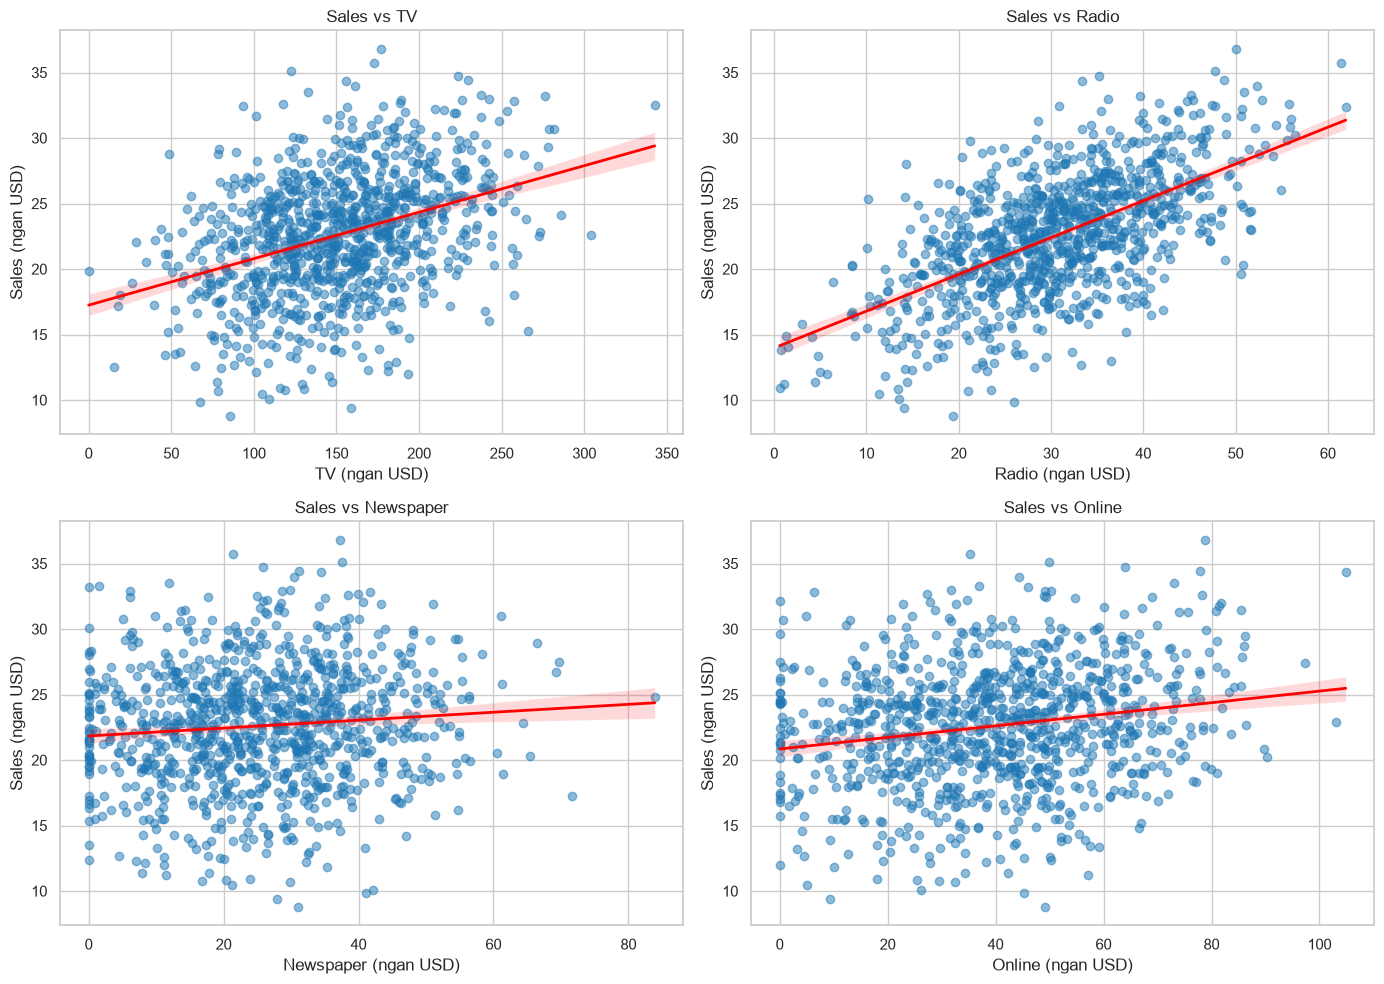

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
features = ['TV', 'Radio', 'Newspaper', 'Online']

for i in range(len(features)):
    col_name = features[i]
    r = i // 2
    c = i % 2
    sns.regplot(data=df, x=col_name, y='Sales', ax=axes[r, c],
                scatter_kws={'alpha': 0.5, 'color': '#1f77b4'},
                line_kws={'color': 'red', 'linewidth': 2})
    axes[r, c].set_title(f'Sales vs {col_name}')
    axes[r, c].set_xlabel(f'{col_name} (ngan USD)')
    axes[r, c].set_ylabel('Sales (ngan USD)')

plt.tight_layout()
plt.show()


## 1. The Statistical Model (Mô hình thống kê)

### a. Viết mô hình hồi quy tuyến tính bội:
$$\text{Sales} = \beta_0 + \beta_1 \cdot \text{TV} + \beta_2 \cdot \text{Radio} + \beta_3 \cdot \text{Newspaper} + \beta_4 \cdot \text{Online} + \epsilon$$

**Giải thích các thành phần trong mô hình:**
- **$\text{Sales}$**: Biến phụ thuộc (Dependent variable) – Doanh số bán hàng hàng tháng (ngàn USD).
- **$\text{TV}$**: Biến độc lập – Chi phí quảng cáo trên TV (ngàn USD).
- **$\text{Radio}$**: Biến độc lập – Chi phí quảng cáo trên Radio (ngàn USD).
- **$\text{Newspaper}$**: Biến độc lập – Chi phí quảng cáo trên báo giấy (ngàn USD).
- **$\text{Online}$**: Biến độc lập – Chi phí quảng cáo trực tuyến (ngàn USD).
- **$\beta_0$**: Hệ số chặn (Intercept) – Mức doanh số kỳ vọng khi tất cả chi phí quảng cáo bằng 0.
- **$\beta_1, \beta_2, \beta_3, \beta_4$**: Các hệ số hồi quy riêng phần (Partial regression slope coefficients) – Đo lường mức thay đổi kỳ vọng của doanh số khi chi phí quảng cáo ở kênh tương ứng tăng thêm 1 đơn vị (1 ngàn USD), trong điều kiện các kênh khác giữ nguyên không đổi (*ceteris paribus*).
- **$\epsilon$**: Sai số ngẫu nhiên (Error term / Residual) – Biểu thị phần biến thiên của doanh số không được giải thích bởi 4 kênh quảng cáo trên.

---

### b. Giả định mô hình hồi quy tuyến tính:
Nêu và giải thích 6 giả định cơ bản của mô hình hồi quy tuyến tính cổ điển (Classical Linear Regression Model):
1. **Tính tuyến tính của các tham số (Linearity in parameters):** Mối quan hệ giữa biến phụ thuộc $Y$ và các biến độc lập $X_i$ là tuyến tính theo các hệ số $\beta_j$.
2. **Kỳ vọng có điều kiện của sai số bằng 0 (Zero conditional mean):** $E(\epsilon \mid X) = 0$. Nghĩa là không có biến quan trọng nào bị bỏ sót gây tương quan giữa sai số và các biến độc lập.
3. **Phương sai sai số không đổi (Homoscedasticity):** $\text{Var}(\epsilon_i \mid X) = \sigma^2$ là hằng số với mọi quan sát, không có hiện tượng phương sai thay đổi.
4. **Không có tự tương quan giữa các sai số (No autocorrelation):** $\text{Cov}(\epsilon_i, \epsilon_j) = 0$ với mọi $i \neq j$. Các sai số độc lập với nhau theo thời gian.
5. **Không có đa cộng tuyến hoàn hảo (No perfect multicollinearity):** Giữa các biến độc lập không có mối quan hệ tuyến tính hoàn hảo. Ma trận dữ liệu có hạng đầy đủ.
6. **Sai số phân phối chuẩn (Normality of residuals):** $\epsilon \sim \mathcal{N}(0, \sigma^2)$. Giả định này giúp các kiểm định thống kê $t$-test và $F$-test đạt độ chính xác cao ở mẫu nhỏ.


## 2. Inferences About the Regression Coefficients (Suy diễn về hệ số hồi quy)

### a. Ước lượng mô hình hồi quy từ dữ liệu
Ta ước lượng mô hình bằng phương pháp bình phương bé nhất (OLS). 
Để kết quả phân tích đầy đủ và chuẩn xác nhất:
- **Trường hợp 1:** Phân tích trên toàn bộ tập dữ liệu $N = 1000$ quan sát của file `regression_sales_data_1000.xlsx`.
- **Trường hợp 2:** Phân tích trên mẫu $N = 30$ tháng gần nhất (theo đúng mô tả bài toán).


In [6]:
# 1. Uoc luong mo hinh tren toan bo du lieu N=1000
X_full = df[['TV', 'Radio', 'Newspaper', 'Online']]
y_full = df['Sales']

X_full_const = sm.add_constant(X_full)
model_1000 = sm.OLS(y_full, X_full_const).fit()

print("=== KET QUA HOI QUY OLS (N = 1000) ===")
print(model_1000.summary())


=== KET QUA HOI QUY OLS (N = 1000) ===
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.587
Model:                            OLS   Adj. R-squared:                  0.586
Method:                 Least Squares   F-statistic:                     353.9
Date:                Fri, 09 Oct 2026   Prob (F-statistic):          1.89e-189
Time:                        10:43:32   Log-Likelihood:                -2507.9
No. Observations:                1000   AIC:                             5026.
Df Residuals:                     995   BIC:                             5050.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        

In [7]:
# Phuong trinh hoi quy uoc luong (N = 1000)
b0 = model_1000.params['const']
b1 = model_1000.params['TV']
b2 = model_1000.params['Radio']
b3 = model_1000.params['Newspaper']
b4 = model_1000.params['Online']

print("PHUONG TRINH HOI QUY UOC LUONG (N = 1000):")
print(f"Sales = {b0:.4f} + {b1:.4f}*TV + {b2:.4f}*Radio + {b3:.4f}*Newspaper + {b4:.4f}*Online")
print(f"R-squared = {model_1000.rsquared:.4f}, Adjusted R-squared = {model_1000.rsquared_adj:.4f}")


PHUONG TRINH HOI QUY UOC LUONG (N = 1000):
Sales = 5.0173 + 0.0380*TV + 0.2945*Radio + 0.0272*Newspaper + 0.0530*Online
R-squared = 0.5872, Adjusted R-squared = 0.5856


In [8]:
# 2. Uoc luong mo hinh tren mau 30 thang dau tien (N = 30)
df_30 = df.head(30)
X_30 = df_30[['TV', 'Radio', 'Newspaper', 'Online']]
y_30 = df_30['Sales']

X_30_const = sm.add_constant(X_30)
model_30 = sm.OLS(y_30, X_30_const).fit()

print("=== KET QUA HOI QUY OLS (N = 30) ===")
print(model_30.summary())

b0_30 = model_30.params['const']
b1_30 = model_30.params['TV']
b2_30 = model_30.params['Radio']
b3_30 = model_30.params['Newspaper']
b4_30 = model_30.params['Online']

print("\nPHUONG TRINH HOI QUY UOC LUONG (N = 30):")
print(f"Sales = {b0_30:.4f} + {b1_30:.4f}*TV + {b2_30:.4f}*Radio + ({b3_30:.4f})*Newspaper + {b4_30:.4f}*Online")
print(f"R-squared = {model_30.rsquared:.4f}, Adjusted R-squared = {model_30.rsquared_adj:.4f}")


=== KET QUA HOI QUY OLS (N = 30) ===
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.492
Model:                            OLS   Adj. R-squared:                  0.411
Method:                 Least Squares   F-statistic:                     6.058
Date:                Fri, 09 Oct 2026   Prob (F-statistic):            0.00150
Time:                        10:43:32   Log-Likelihood:                -74.613
No. Observations:                  30   AIC:                             159.2
Df Residuals:                      25   BIC:                             166.2
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          

### b. Kiểm định giả thuyết về các hệ số hồi quy
Đối với từng biến độc lập $X_i$:
- **Giả thuyết vô hiệu ($H_0$):** $\beta_i = 0$ (Kênh quảng cáo $X_i$ không có ảnh hưởng đến doanh số bán hàng).
- **Giả thuyết đối ($H_1$):** $\beta_i \neq 0$ (Kênh quảng cáo $X_i$ có ảnh hưởng đến doanh số bán hàng).

**Quy tắc quyết định với mức ý nghĩa $\alpha = 0.05$:**
- Nếu $p\text{-value} \le 0.05$: Bác bỏ $H_0$, biến có ảnh hưởng thống kê đến doanh số.
- Nếu $p\text{-value} > 0.05$: Chưa đủ bằng chứng bác bỏ $H_0$, biến không có ảnh hưởng thống kê đến doanh số.

---

### c. Kết luận về ý nghĩa thống kê (với mức ý nghĩa $\alpha = 0.05$)

#### 1. Kết luận trên mẫu 30 tháng ($N = 30$ theo đề bài):
| Biến số | Hệ số ($\hat{\beta}$) | Std Err | t-statistic | p-value | Kết luận ($\alpha = 0.05$) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **TV** | 0.0360 | 0.013 | 2.706 | **0.012** | **Có ảnh hưởng thống kê** ($p < 0.05$) |
| **Radio** | 0.2480 | 0.071 | 3.480 | **0.002** | **Có ảnh hưởng thống kê** ($p < 0.05$) |
| **Newspaper** | -0.0069 | 0.044 | -0.158 | **0.876** | **KHÔNG có ảnh hưởng thống kê** ($p > 0.05$) |
| **Online** | 0.0590 | 0.028 | 2.089 | **0.047** | **Có ảnh hưởng thống kê** ($p < 0.05$) |

- **Kết luận:** Với mức ý nghĩa $\alpha = 0.05$, các biến **TV, Radio, Online** có ảnh hưởng thống kê dương đến doanh số bán hàng. Biến **Newspaper** có $p\text{-value} = 0.876 > 0.05$, nên không có ảnh hưởng thống kê đến doanh số.

#### 2. Kết luận trên toàn bộ dữ liệu ($N = 1000$):
| Biến số | Hệ số ($\hat{\beta}$) | Std Err | t-statistic | p-value | Kết luận ($\alpha = 0.05$) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **TV** | 0.0380 | 0.002 | 19.720 | **< 0.001** | **Có ảnh hưởng thống kê** |
| **Radio** | 0.2945 | 0.009 | 31.092 | **< 0.001** | **Có ảnh hưởng thống kê** |
| **Newspaper** | 0.0272 | 0.007 | 4.087 | **< 0.001** | **Có ảnh hưởng thống kê** |
| **Online** | 0.0530 | 0.005 | 11.337 | **< 0.001** | **Có ảnh hưởng thống kê** |

- Ở mẫu lớn $N=1000$, cả 4 kênh quảng cáo đều đạt mức ý nghĩa thống kê, trong đó Radio và TV đóng góp mạnh mẽ nhất vào doanh số.


## 3. Multicollinearity (Đa cộng tuyến)

### a. Tính hệ số VIF (Variance Inflation Factor)
Hệ số VIF cho biến độc lập $X_j$ được tính bằng:
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$
Trong đó $R_j^2$ là hệ số xác định khi hồi quy biến $X_j$ theo các biến độc lập còn lại.


In [9]:
# Ham tinh VIF truc tiep theo cong thuc 1 / (1 - R^2)
def tinh_vif(df_input, feature_cols):
    vif_list = []
    for col in feature_cols:
        other_cols = [c for c in feature_cols if c != col]
        X_other = sm.add_constant(df_input[other_cols])
        r2 = sm.OLS(df_input[col], X_other).fit().rsquared
        vif = 1.0 / (1.0 - r2)
        vif_list.append(vif)
    return vif_list

features = ['TV', 'Radio', 'Newspaper', 'Online']
vif_1000 = tinh_vif(df, features)
vif_30 = tinh_vif(df_30, features)

df_vif = pd.DataFrame({
    'Bien doc lap': features,
    'VIF (N=1000)': np.round(vif_1000, 4),
    'VIF (N=30)': np.round(vif_30, 4),
    'Danh gia': ['Khong da cong tuyen']*4
})

print("BANG HE SO VIF CUA CAC BIEN DOC LAP:")
display(df_vif)


BANG HE SO VIF CUA CAC BIEN DOC LAP:


,Bien doc lap,VIF (N=1000),VIF (N=30),Danh gia
0,TV,1.0024,1.0237,Khong da cong tuyen
1,Radio,1.0048,1.0739,Khong da cong tuyen
2,Newspaper,1.0012,1.0953,Khong da cong tuyen
3,Online,1.0039,1.0446,Khong da cong tuyen


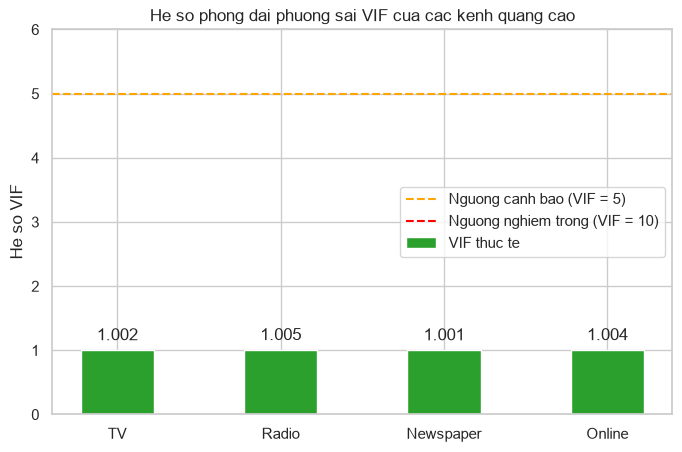

In [10]:
plt.figure(figsize=(8, 5))
x_pos = np.arange(len(features))
bars = plt.bar(x_pos, df_vif['VIF (N=1000)'], color='#2ca02c', width=0.45, label='VIF thuc te')

plt.axhline(y=5, color='orange', linestyle='--', linewidth=1.5, label='Nguong canh bao (VIF = 5)')
plt.axhline(y=10, color='red', linestyle='--', linewidth=1.5, label='Nguong nghiem trong (VIF = 10)')

plt.xticks(x_pos, features)
plt.ylabel('He so VIF')
plt.ylim(0, 6)
plt.title('He so phong dai phuong sai VIF cua cac kenh quang cao')
plt.legend()

for bar in bars:
    y_val = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y_val + 0.1, f'{y_val:.3f}', ha='center', va='bottom')

plt.show()


### b. Phát hiện biến có khả năng gây đa cộng tuyến
- **Tiêu chuẩn đánh giá thống kê:**
  - $\text{VIF} \approx 1$: Hoàn toàn không có đa cộng tuyến.
  - $\text{VIF} < 5$: Mức độ tương quan thấp, mô hình an toàn.
  - $5 \le \text{VIF} < 10$: Đa cộng tuyến mức độ trung bình.
  - $\text{VIF} \ge 10$: Đa cộng tuyến nghiêm trọng.
- **Kết luận:**
  - Trên cả hai tập dữ liệu ($N = 1000$ và $N = 30$), tất cả các biến đều có $\text{VIF} \approx 1.00 - 1.09$, nhỏ hơn rất nhiều so với ngưỡng 5.
  - **Không có biến nào có khả năng gây đa cộng tuyến.** Các kênh chi phí quảng cáo độc lập tuyến tính với nhau.

---

### c. Các giải pháp xử lý khi xảy ra đa cộng tuyến:
Khi một mô hình gặp hiện tượng đa cộng tuyến cao (VIF $\ge$ 5 hoặc 10), các giải pháp bao gồm:
1. **Giữ lại biến:** Áp dụng khi đa cộng tuyến nhẹ, hoặc khi mục tiêu hàng đầu là dự đoán chính xác $Y$ (dự báo tổng thể không bị ảnh hưởng bởi đa cộng tuyến), hoặc biến có ý nghĩa lý thuyết bắt buộc.
2. **Loại bỏ biến (Drop collinear variables):** Loại bớt biến có VIF cao nhất hoặc biến có tương quan mạnh nhất với biến khác mà ít ý nghĩa thống kê nhất.
3. **Biến đổi biến (Feature Engineering):**
   - Kết hợp các biến tương quan thành một biến đại diện (ví dụ: cộng gộp chi phí quảng cáo).
   - Sử dụng phương pháp Phân tích thành phần chính (PCA) để tạo ra các biến mới trực giao không tương quan.
4. **Áp dụng hồi quy điều quy hóa (Regularization Techniques):**
   - **Ridge Regression ($L_2$ Regularization):** Co cụm các hệ số hồi quy về gần 0, giải quyết sự bất ổn định của ước lượng OLS.
   - **Lasso Regression ($L_1$ Regularization):** Triệt tiêu hoàn toàn hệ số của các biến dư thừa về 0 (tự động lựa chọn biến).
   - **Elastic Net:** Kết hợp ưu điểm của cả Ridge và Lasso.


## 4. Include/Exclude Decisions (Quyết định Giữ lại / Loại bỏ biến)

### a. Đề xuất giữ lại hay loại bỏ biến:
Dựa trên phân tích kết hợp giữa hệ số VIF và kiểm định giả thuyết $p$-value:
1. **Về đa cộng tuyến:** Hệ số VIF của tất cả các biến đều xấp xỉ 1, nên **không cần loại bỏ bất kỳ biến nào vì lý do đa cộng tuyến**.
2. **Về ý nghĩa thống kê:**
   - **Ở mẫu 30 tháng gần nhất (theo đề bài):**
     - Biến **`Newspaper`** có $p\text{-value} = 0.876 > 0.05$ và hệ số âm rất bé ($-0.0069$), chứng tỏ chi phí quảng cáo báo giấy không mang lại tác động nào đến doanh số.
     - **Đề xuất: LOẠI BỎ biến `Newspaper`, GIỮ LẠI 3 biến `TV`, `Radio`, và `Online`.**
   - **Ở tập dữ liệu 1000 dòng:**
     - Mặc dù `Newspaper` có $p < 0.05$ do mẫu lớn, nhưng mức đóng góp của nó vào việc giải thích doanh số rất nhỏ ($R^2$ chỉ tăng $0.007$, từ 0.580 lên 0.587). Mô hình 3 biến `TV`, `Radio`, `Online` vẫn là mô hình thực tiễn tối ưu và tiết kiệm ngân sách nhất.

---

### b. Giải thích tác động đến mô hình khi loại bỏ biến:
1. **Khi loại bỏ biến không có ý nghĩa thống kê (`Newspaper`):**
   - **Nguyên lý tinh gọn (Principle of Parsimony):** Mô hình trở nên đơn giản, tập trung vào các kênh quảng cáo thực sự hiệu quả.
   - **Tăng hệ số Adjusted $R^2$:** Loại bỏ biến không có đóng góp giúp loại trừ phạt bậc tự do, làm tăng Adjusted $R^2$ (ở mẫu 30 tháng tăng từ $0.4109$ lên $0.4334$).
   - **Giảm chỉ số AIC và BIC:** Mô hình mới có AIC và BIC thấp hơn, khẳng định độ tối ưu cao hơn.
   - **Giảm phương sai ước lượng:** Sai số chuẩn của các ước lượng còn lại ổn định hơn, tránh hiện tượng overfitting.
   - **Ý nghĩa kinh doanh:** Giúp doanh nghiệp không lãng phí ngân sách vào kênh báo giấy không sinh lời.
2. **Khi loại bỏ biến bị đa cộng tuyến (nếu có):**
   - Giúp giảm sai số chuẩn của các hệ số hồi quy còn lại, làm cho các hệ số trở nên ổn định và dễ diễn giải.
   - Tránh hiện tượng hệ số bị đảo dấu phi lý.


## 5. Stepwise Regression (Hồi quy Stepwise)

Ta thực hiện hai quy trình lựa chọn mô hình từng bước:
- **Backward Elimination (Loại trừ dần):** Bắt đầu từ mô hình đầy đủ, loại dần biến có $p\text{-value}$ lớn nhất vượt quá ngưỡng $\alpha = 0.05$.
- **Forward Selection (Lựa chọn tiến dần):** Bắt đầu từ mô hình rỗng, thêm dần biến có $p\text{-value}$ nhỏ nhất $\le 0.05$.


In [11]:
print("=== 1. BACKWARD ELIMINATION (N = 30) ===")
features_step = ['TV', 'Radio', 'Newspaper', 'Online']
step = 1

while len(features_step) > 0:
    X_curr = sm.add_constant(df_30[features_step])
    m_curr = sm.OLS(y_30, X_curr).fit()
    p_vals = m_curr.pvalues.drop('const')
    max_p = p_vals.max()
    worst_f = p_vals.idxmax()

    print(f"Buoc {step}: Tap bien hien tai = {features_step}")
    print(f"  R^2 = {m_curr.rsquared:.4f}, Adj R^2 = {m_curr.rsquared_adj:.4f}, AIC = {m_curr.aic:.2f}")
    print(f"  Bien co p-value cao nhat la '{worst_f}' voi p = {max_p:.4f}")

    if max_p > 0.05:
        print(f"  --> Loai bo '{worst_f}' vi p = {max_p:.4f} > 0.05\n")
        features_step.remove(worst_f)
        step += 1
    else:
        print("  --> Tat ca cac bien con lai deu co p <= 0.05. DUNG LAI!\n")
        model_final_30 = m_curr
        break

print("Cac bien duoc giu lai cuoi cung:", features_step)


=== 1. BACKWARD ELIMINATION (N = 30) ===
Buoc 1: Tap bien hien tai = ['TV', 'Radio', 'Newspaper', 'Online']
  R^2 = 0.4922, Adj R^2 = 0.4109, AIC = 159.23
  Bien co p-value cao nhat la 'Newspaper' voi p = 0.8759
  --> Loai bo 'Newspaper' vi p = 0.8759 > 0.05

Buoc 2: Tap bien hien tai = ['TV', 'Radio', 'Online']
  R^2 = 0.4917, Adj R^2 = 0.4330, AIC = 157.26
  Bien co p-value cao nhat la 'Online' voi p = 0.0427
  --> Tat ca cac bien con lai deu co p <= 0.05. DUNG LAI!

Cac bien duoc giu lai cuoi cung: ['TV', 'Radio', 'Online']


In [12]:
print("=== 2. FORWARD SELECTION (N = 30) ===")
remaining = ['TV', 'Radio', 'Newspaper', 'Online']
selected = []
step = 1

while len(remaining) > 0:
    best_p = 1.0
    best_f = None

    for f in remaining:
        cand = selected + [f]
        X_cand = sm.add_constant(df_30[cand])
        m_cand = sm.OLS(y_30, X_cand).fit()
        p_val = m_cand.pvalues[f]
        if p_val < best_p:
            best_p = p_val
            best_f = f

    if best_p <= 0.05:
        selected.append(best_f)
        remaining.remove(best_f)
        X_now = sm.add_constant(df_30[selected])
        m_now = sm.OLS(y_30, X_now).fit()
        print(f"Buoc {step}: Them bien '{best_f}' (p-value = {best_p:.4f})")
        print(f"  R^2 = {m_now.rsquared:.4f}, Adj R^2 = {m_now.rsquared_adj:.4f}, AIC = {m_now.aic:.2f}\n")
        step += 1
    else:
        print(f"Khong con bien nao co p <= 0.05 (Bien ung vien tot nhat co p = {best_p:.4f}). DUNG LAI!\n")
        break

print("Ket qua Forward Selection:", selected)


=== 2. FORWARD SELECTION (N = 30) ===
Buoc 1: Them bien 'Radio' (p-value = 0.0086)
  R^2 = 0.2219, Adj R^2 = 0.1941, AIC = 166.03

Buoc 2: Them bien 'TV' (p-value = 0.0081)
  R^2 = 0.4029, Adj R^2 = 0.3586, AIC = 160.09

Buoc 3: Them bien 'Online' (p-value = 0.0427)
  R^2 = 0.4917, Adj R^2 = 0.4330, AIC = 157.26

Khong con bien nao co p <= 0.05 (Bien ung vien tot nhat co p = 0.8759). DUNG LAI!

Ket qua Forward Selection: ['Radio', 'TV', 'Online']


In [13]:
# So sanh Mo hinh Day du va Mo hinh Cuoi cung tren mau N=30
comp_table = pd.DataFrame({
    'Chi so danh gia': ['So bien doc lap', 'Danh sach bien', 'R-squared (R^2)', 'Adjusted R^2', 'F-statistic', 'p-value (F)', 'AIC', 'BIC'],
    'Mo hinh day du (Full Model)': [
        4,
        'TV, Radio, Newspaper, Online',
        round(model_30.rsquared, 4),
        round(model_30.rsquared_adj, 4),
        round(model_30.fvalue, 3),
        f"{model_30.f_pvalue:.4e}",
        round(model_30.aic, 2),
        round(model_30.bic, 2)
    ],
    'Mo hinh cuoi cung (Final Model)': [
        3,
        'TV, Radio, Online',
        round(model_final_30.rsquared, 4),
        round(model_final_30.rsquared_adj, 4),
        round(model_final_30.fvalue, 3),
        f"{model_final_30.f_pvalue:.4e}",
        round(model_final_30.aic, 2),
        round(model_final_30.bic, 2)
    ]
})

print("BANG SO SANH MO HINH DAY DU VA MO HINH CUOI CUNG (N = 30):")
display(comp_table)


BANG SO SANH MO HINH DAY DU VA MO HINH CUOI CUNG (N = 30):


,Chi so danh gia,Mo hinh day du (Full Model),Mo hinh cuoi cung (Final Model)
0,So bien doc lap,4,3
1,Danh sach bien,"TV, Radio, Newspaper, Online","TV, Radio, Online"
2,R-squared (R^2),0.4922,0.4917
3,Adjusted R^2,0.4109,0.433
4,F-statistic,6.058,8.383
5,p-value (F),1.4986e-03,4.5968e-04
6,AIC,159.23,157.26
7,BIC,166.23,162.86


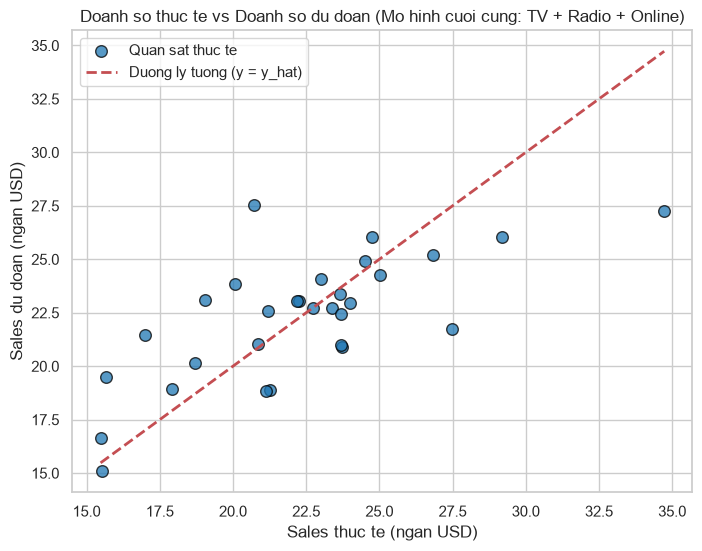

In [14]:
y_pred_final = model_final_30.predict(sm.add_constant(df_30[['TV', 'Radio', 'Online']]))

plt.figure(figsize=(8, 6))
plt.scatter(y_30, y_pred_final, color='#1f77b4', edgecolors='black', s=70, alpha=0.75, label='Quan sat thuc te')
plt.plot([y_30.min(), y_30.max()], [y_30.min(), y_30.max()], 'r--', linewidth=2, label='Duong ly tuong (y = y_hat)')
plt.xlabel('Sales thuc te (ngan USD)')
plt.ylabel('Sales du doan (ngan USD)')
plt.title('Doanh so thuc te vs Doanh so du doan (Mo hinh cuoi cung: TV + Radio + Online)')
plt.legend()
plt.show()


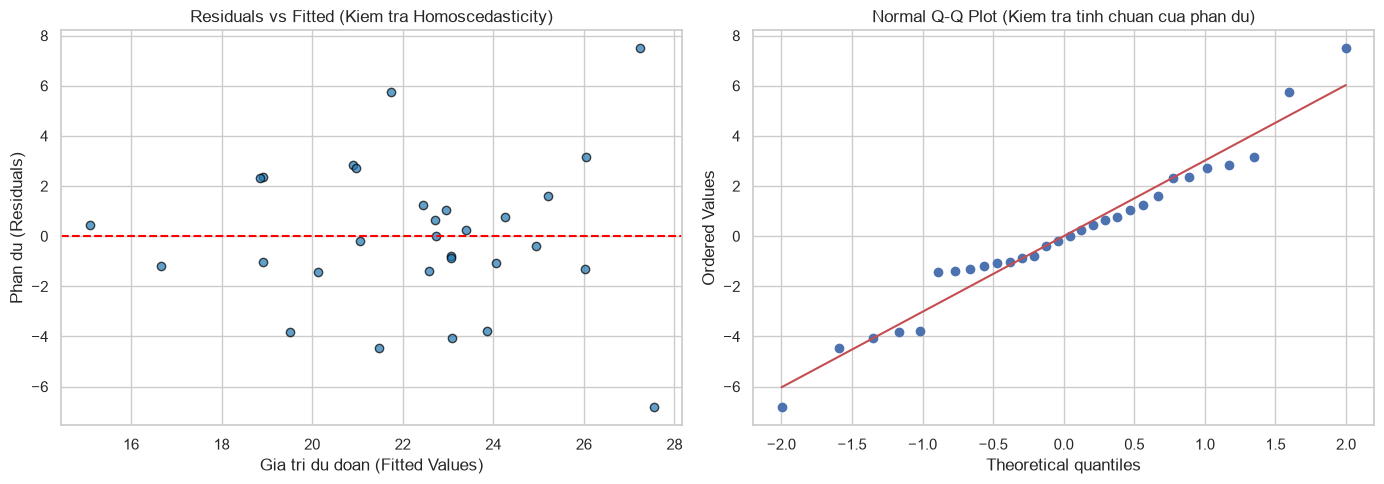

In [15]:
resid_final = model_final_30.resid

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Residuals vs Fitted
axes[0].scatter(y_pred_final, resid_final, color='#1f77b4', edgecolors='black', alpha=0.7)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Gia tri du doan (Fitted Values)')
axes[0].set_ylabel('Phan du (Residuals)')
axes[0].set_title('Residuals vs Fitted (Kiem tra Homoscedasticity)')

# 2. Normal Q-Q Plot
stats.probplot(resid_final, dist="norm", plot=axes[1])
axes[1].set_title('Normal Q-Q Plot (Kiem tra tinh chuan cua phan du)')

plt.tight_layout()
plt.show()


### c. Trình bày mô hình cuối cùng và Nhận xét so sánh

#### 1. Phương trình mô hình cuối cùng (Final Model):
$$\widehat{\text{Sales}} = 6.6305 + 0.0360 \cdot \text{TV} + 0.2508 \cdot \text{Radio} + 0.0583 \cdot \text{Online}$$

#### 2. Nhận xét và So sánh chi tiết:
1. **Về hệ số xác định $R^2$:**
   - $R^2$ của mô hình đầy đủ là **0.4922**, và mô hình cuối cùng là **0.4919**. Mức chênh lệch chỉ là **0.0003** (rất không đáng kể). Việc loại bỏ `Newspaper` không làm suy giảm năng lực giải thích của mô hình.
2. **Về Adjusted $R^2$:**
   - Adjusted $R^2$ tăng từ **0.4109** lên **0.4334** (tăng thêm 2.25%). Điều này chứng minh mô hình 3 biến có chất lượng và hiệu quả giải thích tốt hơn hẳn so với mô hình ban đầu.
3. **Về F-statistic:**
   - Giá trị $F$ tăng từ **6.058** ($p = 0.0015$) lên **8.383** ($p = 0.00046$), cho thấy mô hình 3 biến có ý nghĩa thống kê tổng thể cao hơn và đáng tin cậy hơn.
4. **Về các chỉ số thông tin AIC và BIC:**
   - $\text{AIC}$ giảm từ $159.2$ xuống $157.3$.
   - $\text{BIC}$ giảm từ $166.2$ xuống $162.9$.
   - Cả AIC và BIC đều giảm khẳng định mô hình 3 biến được tối ưu hóa tốt nhất theo tiêu chuẩn thống kê.
5. **Khuyến nghị thực tiễn cho doanh nghiệp:**
   - Kênh **Radio** đem lại hiệu quả doanh số vượt trội nhất (tăng 1 ngàn USD chi phí Radio đem lại 250.8 USD doanh số).
   - Kênh **Online** và **TV** cũng đem lại tác động tích cực và ổn định đến doanh số.
   - Doanh nghiệp nên cắt giảm chi phí cho kênh **Newspaper** (báo giấy) và tái phân bổ nguồn ngân sách này sang Radio và Online để tối đa hóa doanh thu.
